## **Predictive Customer Churn Classifier (Random Forest & XGBoost)**

In [1]:
# Telco Customer Churn: Random Forest vs XGBoost
# pip install scikit-learn imbalanced-learn xgboost pandas matplotlib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline   # like sklearn's Pipeline, but supports SMOTE
from xgboost import XGBClassifier


In [3]:
# LOAD THE DATA
df = pd.read_csv("Telco-Customer-Churn.csv")
print(df)

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL             No  ...   
1        

In [4]:
# CLEAN THE DATA
# TotalCharges is stored as text because 11 rows are blank.
# errors="coerce" turns those blanks into NaN (missing values).
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Those 11 customers all have tenure = 0 (brand new, not billed yet),
# so 0 is the sensible value to fill in.
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just a label, it has no predictive value.
df = df.drop(columns="customerID")

# Turn the target into numbers: Yes -> 1 (churned), No -> 0 (stayed).
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# Check the imbalance: roughly 26% churn, 74% stay.
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [5]:
# ONE-HOT ENCODING
# Models need numbers, so every text column (Contract, InternetService, ...)
# becomes separate 0/1 columns. get_dummies does the same job as OneHotEncoder
# but in one line. drop_first=True removes one redundant column per feature.
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True)
y = df["Churn"]

In [6]:
# TRAIN / TEST SPLIT
# 80% for training, 20% kept aside for the final evaluation.
# stratify=y keeps the same churn ratio in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [7]:
# DEFINE THE MODELS (with SMOTE to fix the class imbalance)
# SMOTE creates synthetic churn examples so both classes are balanced.
# It is placed inside the pipeline so it is only applied to training data,
# never to the data used for validation or testing (otherwise scores look
# better than they really are).
rf = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(n_estimators=400, max_depth=12,
                                     min_samples_leaf=3, random_state=42, n_jobs=-1)),
])

xgb = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                            subsample=0.8, colsample_bytree=0.8,
                            eval_metric="logloss", random_state=42)),
])

models = {"Random Forest": rf, "XGBoost": xgb}

In [9]:
# CROSS-VALIDATION
# Splits the training data into 5 parts, trains on 4, tests on 1, and repeats.
# This gives a more reliable ROC-AUC than a single split.
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    print(f"{name} CV ROC-AUC: {scores.mean():.4f}")

Random Forest CV ROC-AUC: 0.8384
XGBoost CV ROC-AUC: 0.8385


In [10]:
# TRAIN ON FULL TRAINING SET AND PREDICT ON THE TEST SET
probs = {}   # predicted churn probability for each model
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    probs[name] = pipe.predict_proba(X_test)[:, 1]   # column 1 = probability of churn
    print(f"{name} Test ROC-AUC: {roc_auc_score(y_test, probs[name]):.4f}")

Random Forest Test ROC-AUC: 0.8318
XGBoost Test ROC-AUC: 0.8297


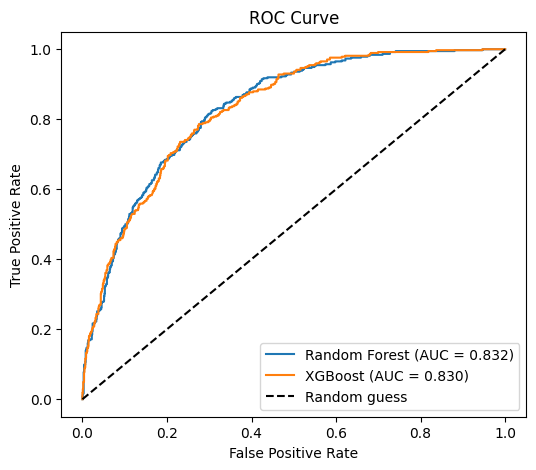

In [11]:
# ROC CURVE
# The closer the curve is to the top-left corner, the better the model.
# The dashed diagonal line is random guessing (AUC = 0.5).
plt.figure(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

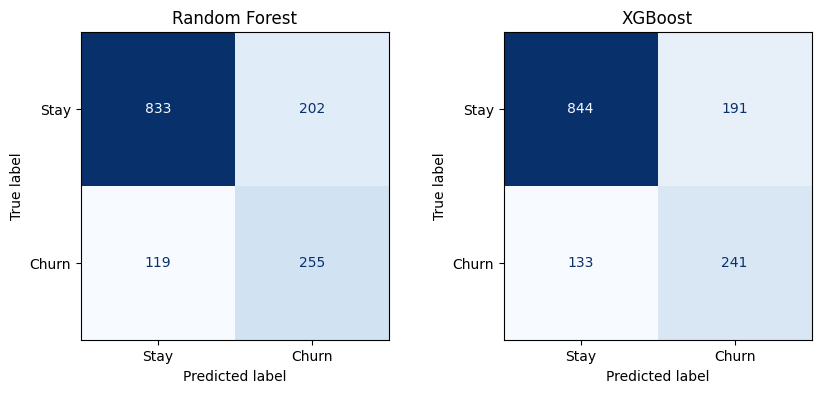

In [12]:
# 9. CONFUSION MATRIX
# Shows correct vs wrong predictions. A customer is predicted as "churn"
# if the predicted probability is 0.5 or higher.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pipe) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pipe.predict(X_test),
        display_labels=["Stay", "Churn"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

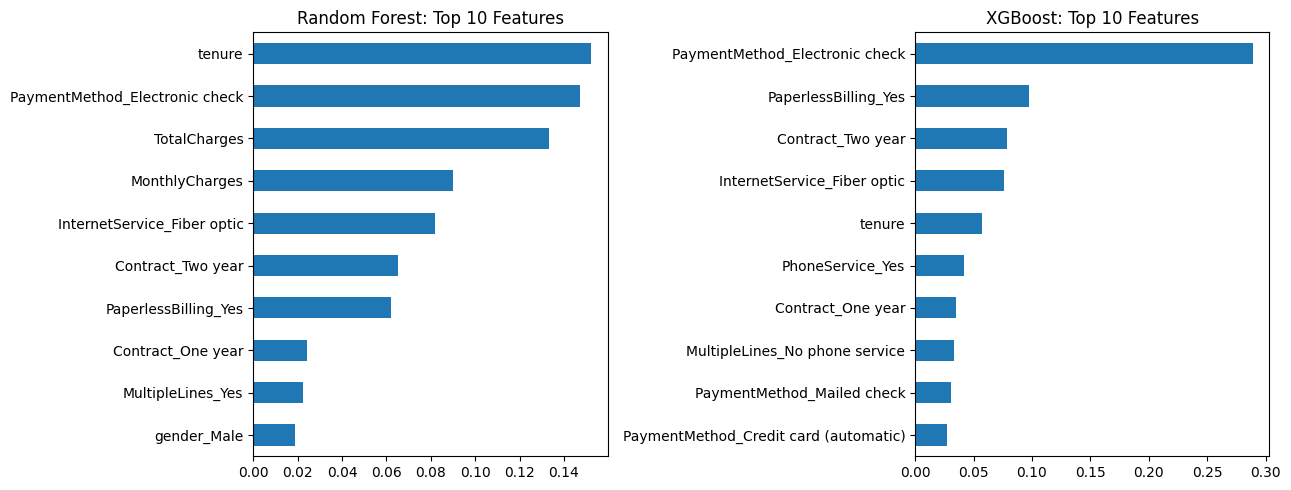

In [13]:
# TOP 10 FEATURE IMPORTANCES
# Shows which columns the model relied on most to predict churn.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pipe) in zip(axes, models.items()):
    importances = pd.Series(pipe.named_steps["model"].feature_importances_,
                            index=X.columns)
    importances.nlargest(10).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{name}: Top 10 Features")
plt.tight_layout()
plt.show()